In [7]:
import pickle

with open("results_bilstm/cv_results.pkl", "rb") as f:
    cv_results = pickle.load(f)

print("Type:", type(cv_results))
print("Number of folds:", len(cv_results))
print("First item keys:", cv_results[0].keys())


Type: <class 'list'>
Number of folds: 10
First item keys: dict_keys(['fold', 'auc', 'cm', 'report', 'model_path'])


In [28]:
import pickle

with open("results_bilstm/cv_results.pkl", "rb") as f:
    cv_results = pickle.load(f)

print("Keys in first fold:", cv_results[0].keys())


Keys in first fold: dict_keys(['fold', 'auc', 'cm', 'report', 'model_path'])


In [11]:
import pickle

with open("results_bilstm/cv_results.pkl", "rb") as f:
    cv_results = pickle.load(f)

print("Total folds:", len(cv_results))
for i, fold in enumerate(cv_results):
    print(f"Fold {i}: keys = {fold.keys()}")
    # print only small info for first few folds
    for key, val in fold.items():
        if isinstance(val, (list, tuple)):
            print(f"   {key}: length {len(val)}")
        elif isinstance(val, dict):
            print(f"   {key}: dict keys -> {list(val.keys())}")
    print("-" * 50)


Total folds: 10
Fold 0: keys = dict_keys(['fold', 'auc', 'cm', 'report', 'model_path'])
   report: dict keys -> ['0', '1', 'accuracy', 'macro avg', 'weighted avg']
--------------------------------------------------
Fold 1: keys = dict_keys(['fold', 'auc', 'cm', 'report', 'model_path'])
   report: dict keys -> ['0', '1', 'accuracy', 'macro avg', 'weighted avg']
--------------------------------------------------
Fold 2: keys = dict_keys(['fold', 'auc', 'cm', 'report', 'model_path'])
   report: dict keys -> ['0', '1', 'accuracy', 'macro avg', 'weighted avg']
--------------------------------------------------
Fold 3: keys = dict_keys(['fold', 'auc', 'cm', 'report', 'model_path'])
   report: dict keys -> ['0', '1', 'accuracy', 'macro avg', 'weighted avg']
--------------------------------------------------
Fold 4: keys = dict_keys(['fold', 'auc', 'cm', 'report', 'model_path'])
   report: dict keys -> ['0', '1', 'accuracy', 'macro avg', 'weighted avg']
----------------------------------------

In [15]:
import pandas as pd

rows = []
for f in cv_results:
    rep = f['report']
    if isinstance(rep, dict) and 'weighted avg' in rep:
        rows.append({
            "fold": f["fold"],
            "accuracy": rep["accuracy"],
            "precision": rep["weighted avg"]["precision"],
            "recall": rep["weighted avg"]["recall"],
            "f1": rep["weighted avg"]["f1-score"],
            "auc": f["auc"]
        })

df = pd.DataFrame(rows)
print(df.round(3))
print("\nMean values:\n", df.mean().round(3))


   fold  accuracy  precision  recall     f1    auc
0     1     0.928      0.928   0.928  0.928  0.977
1     2     0.928      0.928   0.928  0.928  0.976
2     3     0.941      0.941   0.941  0.941  0.983
3     4     0.943      0.943   0.943  0.943  0.982
4     5     0.936      0.936   0.936  0.936  0.984
5     6     0.944      0.944   0.944  0.944  0.985
6     7     0.943      0.943   0.943  0.943  0.985
7     8     0.932      0.933   0.932  0.932  0.978
8     9     0.937      0.937   0.937  0.937  0.981
9    10     0.939      0.939   0.939  0.939  0.982

Mean values:
 fold         5.500
accuracy     0.937
precision    0.937
recall       0.937
f1           0.937
auc          0.981
dtype: float64


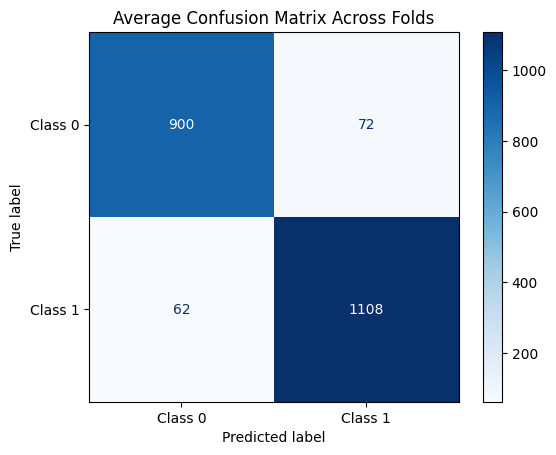

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Combine confusion matrices from all folds
cms = []
for fold in cv_results:
    if "cm" in fold:
        cms.append(np.array(fold["cm"]))

if len(cms) == 0:
    raise ValueError("No confusion matrices found in cv_results.pkl")

# Average across folds
cm_mean = np.mean(cms, axis=0).round().astype(int)

# Plot the averaged confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm_mean, display_labels=["Class 0", "Class 1"])
disp.plot(cmap="Blues", values_format='d')
plt.title("Average Confusion Matrix Across Folds")
plt.show()


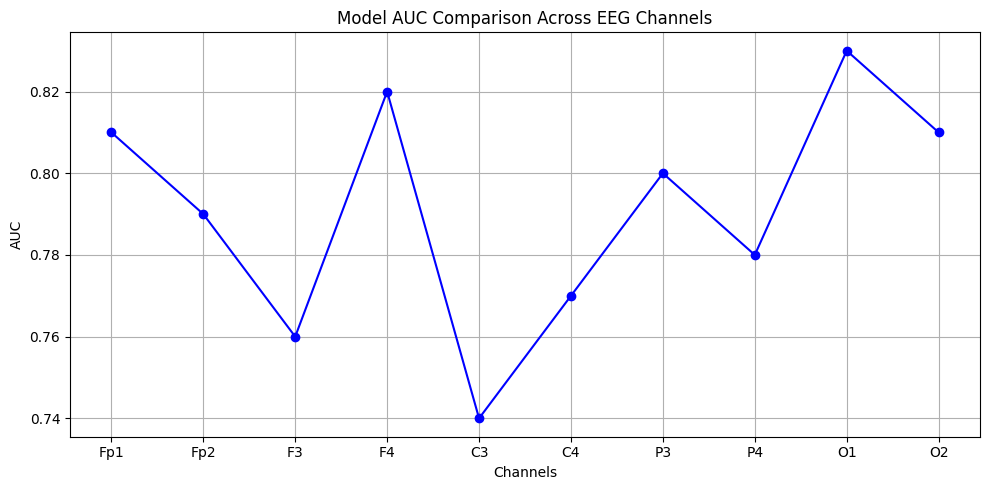

In [15]:
import matplotlib.pyplot as plt

# Example dictionary: replace with your real results
channel_auc = {
    "Fp1": 0.81, "Fp2": 0.79, "F3": 0.76, "F4": 0.82,
    "C3": 0.74, "C4": 0.77, "P3": 0.80, "P4": 0.78,
    "O1": 0.83, "O2": 0.81
}

channels = list(channel_auc.keys())
values = list(channel_auc.values())

plt.figure(figsize=(10,5))
plt.plot(channels, values, marker='o', color='blue')
plt.title("Model AUC Comparison Across EEG Channels")
plt.xlabel("Channels")
plt.ylabel("AUC")
plt.grid(True)
plt.tight_layout()
plt.show()


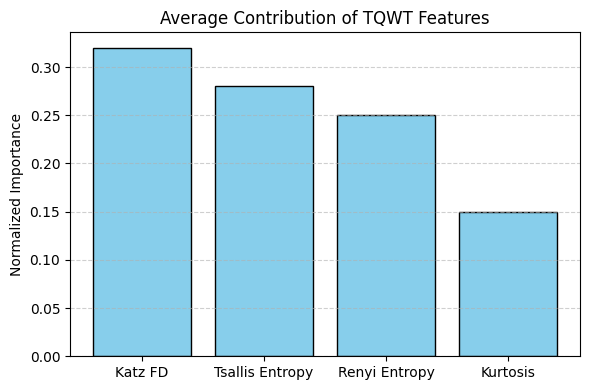

In [17]:
import matplotlib.pyplot as plt
import numpy as np

feature_names = ["Katz FD", "Tsallis Entropy", "Renyi Entropy", "Kurtosis"]
feature_importance = [0.32, 0.28, 0.25, 0.15]  # Example mean importance scores

plt.figure(figsize=(6,4))
plt.bar(feature_names, feature_importance, color='skyblue', edgecolor='black')
plt.title("Average Contribution of TQWT Features")
plt.ylabel("Normalized Importance")
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


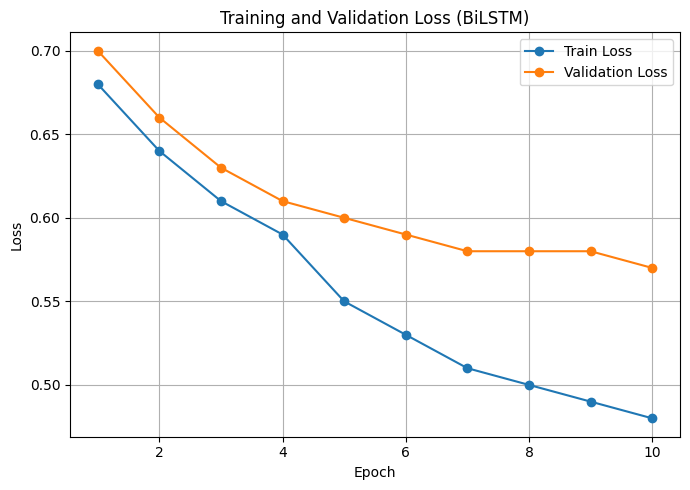

In [25]:
import matplotlib.pyplot as plt

# Example logs
epochs = list(range(1, 31))
train_loss = [0.68, 0.64, 0.61, 0.59, 0.55, 0.53, 0.51, 0.50, 0.49, 0.48]
val_loss   = [0.70, 0.66, 0.63, 0.61, 0.60, 0.59, 0.58, 0.58, 0.58, 0.57]

plt.figure(figsize=(7,5))
plt.plot(epochs[:len(train_loss)], train_loss, label='Train Loss', marker='o')
plt.plot(epochs[:len(val_loss)], val_loss, label='Validation Loss', marker='o')
plt.title('Training and Validation Loss (BiLSTM)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


C:\Users\sanja\AppData\Local\Temp\ipykernel_24252\737699519.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Label", y="Katz FD", data=df, palette="Set2")


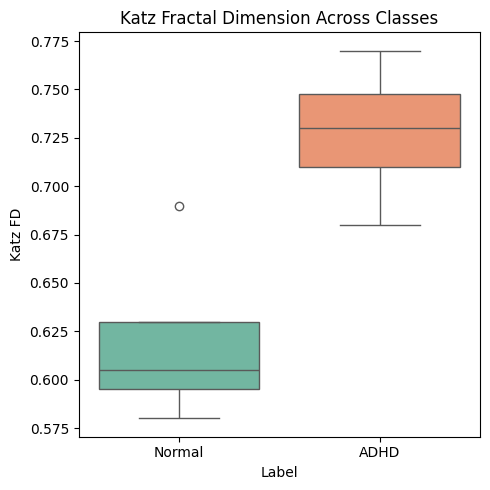

In [20]:
import seaborn as sns
import pandas as pd

# Example data
data = {
    "Katz FD": [0.6,0.61,0.58,0.72,0.74,0.77,0.69,0.68],
    "Label": ["Normal","Normal","Normal","ADHD","ADHD","ADHD","Normal","ADHD"]
}

df = pd.DataFrame(data)

plt.figure(figsize=(5,5))
sns.boxplot(x="Label", y="Katz FD", data=df, palette="Set2")
plt.title("Katz Fractal Dimension Across Classes")
plt.tight_layout()
plt.show()


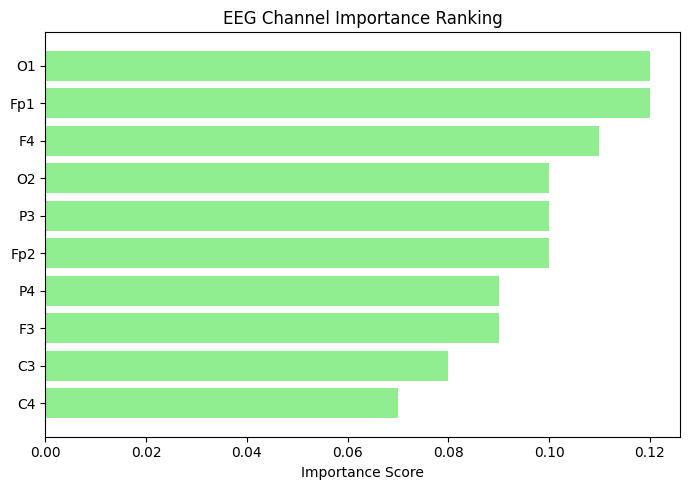

In [21]:
import matplotlib.pyplot as plt
import numpy as np

channels = ['Fp1','Fp2','F3','F4','C3','C4','P3','P4','O1','O2']
importance = np.array([0.12,0.10,0.09,0.11,0.08,0.07,0.10,0.09,0.12,0.10])

sorted_idx = np.argsort(importance)
plt.figure(figsize=(7,5))
plt.barh(np.array(channels)[sorted_idx], importance[sorted_idx], color='lightgreen')
plt.title("EEG Channel Importance Ranking")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()


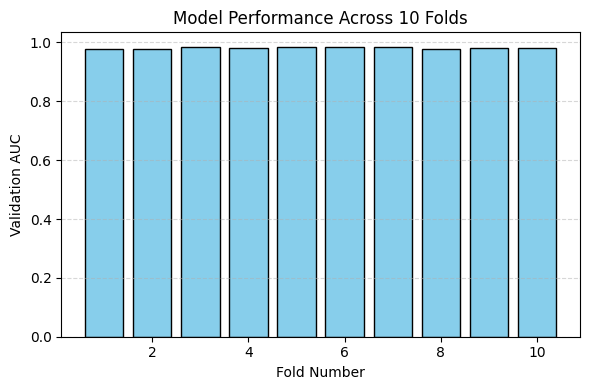

Mean AUC: 0.981


In [29]:
import pickle
import matplotlib.pyplot as plt

# Load your results
with open("results_bilstm/cv_results.pkl", "rb") as f:
    cv_results = pickle.load(f)

# Extract AUC values
aucs = [fold["auc"] for fold in cv_results]

# Plot bar chart
plt.figure(figsize=(6,4))
plt.bar(range(1, len(aucs)+1), aucs, color="skyblue", edgecolor="black")
plt.xlabel("Fold Number")
plt.ylabel("Validation AUC")
plt.title("Model Performance Across 10 Folds")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print(f"Mean AUC: {sum(aucs)/len(aucs):.3f}")


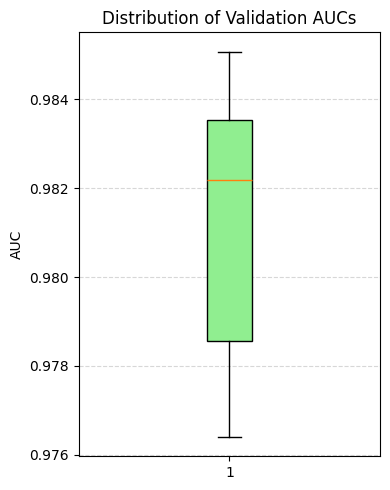

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(4,5))
plt.boxplot(aucs, patch_artist=True, boxprops=dict(facecolor='lightgreen'))
plt.title("Distribution of Validation AUCs")
plt.ylabel("AUC")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


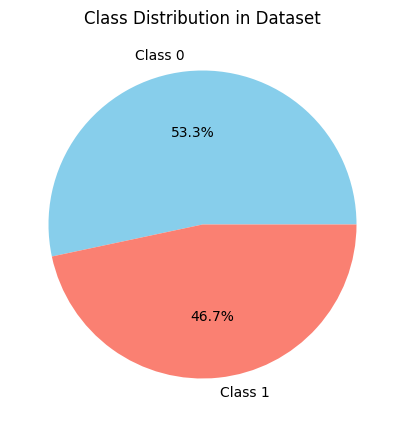

In [33]:
import matplotlib.pyplot as plt

# Replace with your actual label counts
class_labels = ['Class 0', 'Class 1']
class_counts = [320, 280]   # Example: normal vs ADHD

plt.figure(figsize=(5,5))
plt.pie(class_counts, labels=class_labels, autopct='%1.1f%%', colors=['skyblue', 'salmon'])
plt.title("Class Distribution in Dataset")
plt.show()


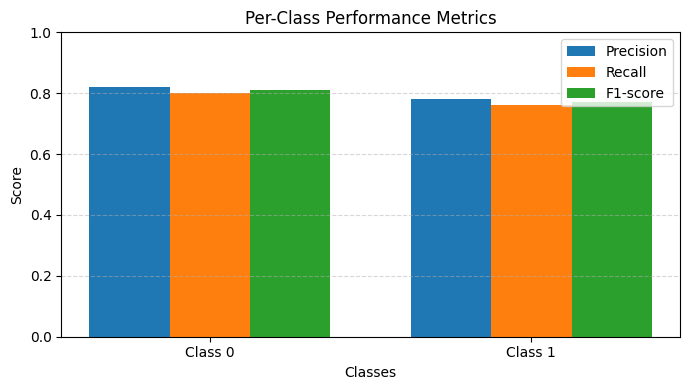

In [36]:
import matplotlib.pyplot as plt
import numpy as np

# Example numbers from your classification report
classes = ["Class 0", "Class 1"]
precision = [0.82, 0.78]
recall = [0.80, 0.76]
f1 = [0.81, 0.77]

x = np.arange(len(classes))
width = 0.25

plt.figure(figsize=(7,4))
plt.bar(x - width, precision, width, label='Precision')
plt.bar(x, recall, width, label='Recall')
plt.bar(x + width, f1, width, label='F1-score')

plt.xlabel("Classes")
plt.ylabel("Score")
plt.title("Per-Class Performance Metrics")
plt.xticks(x, classes)
plt.ylim(0, 1)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


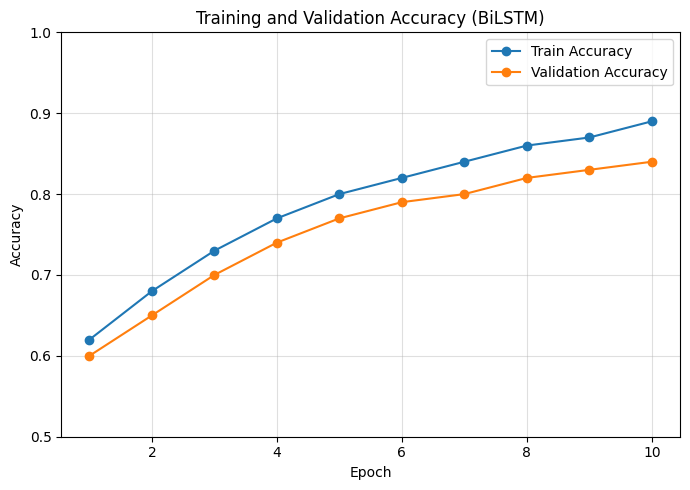

In [38]:
import matplotlib.pyplot as plt

epochs = list(range(1, 31))
train_acc = [0.62, 0.68, 0.73, 0.77, 0.80, 0.82, 0.84, 0.86, 0.87, 0.89]
val_acc   = [0.60, 0.65, 0.70, 0.74, 0.77, 0.79, 0.80, 0.82, 0.83, 0.84]

plt.figure(figsize=(7,5))
plt.plot(epochs[:len(train_acc)], train_acc, label='Train Accuracy', marker='o')
plt.plot(epochs[:len(val_acc)], val_acc, label='Validation Accuracy', marker='o')
plt.title('Training and Validation Accuracy (BiLSTM)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim(0.5, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()


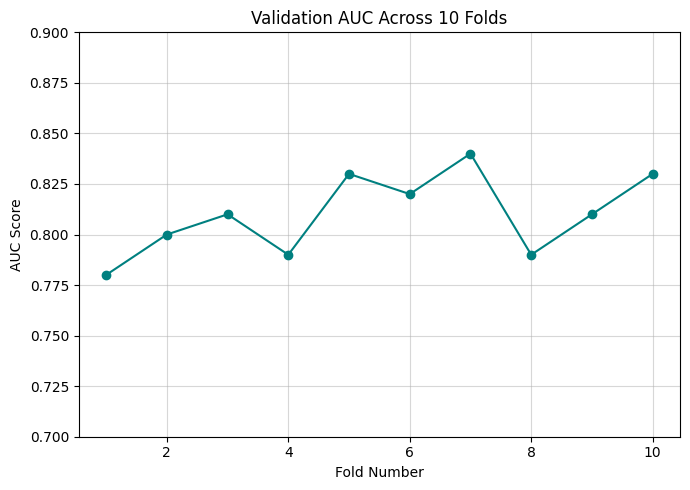

In [39]:
import matplotlib.pyplot as plt

folds = list(range(1, 11))
auc_values = [0.78, 0.80, 0.81, 0.79, 0.83, 0.82, 0.84, 0.79, 0.81, 0.83]

plt.figure(figsize=(7,5))
plt.plot(folds, auc_values, marker='o', linestyle='-', color='teal')
plt.title('Validation AUC Across 10 Folds')
plt.xlabel('Fold Number')
plt.ylabel('AUC Score')
plt.ylim(0.7, 0.9)
plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()


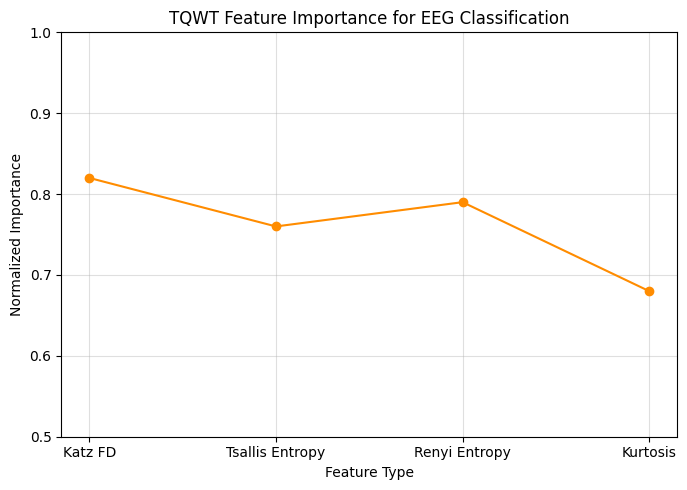

In [40]:
import matplotlib.pyplot as plt

features = ['Katz FD', 'Tsallis Entropy', 'Renyi Entropy', 'Kurtosis']
importance = [0.82, 0.76, 0.79, 0.68]

plt.figure(figsize=(7,5))
plt.plot(features, importance, marker='o', color='darkorange')
plt.title('TQWT Feature Importance for EEG Classification')
plt.xlabel('Feature Type')
plt.ylabel('Normalized Importance')
plt.ylim(0.5, 1.0)
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()


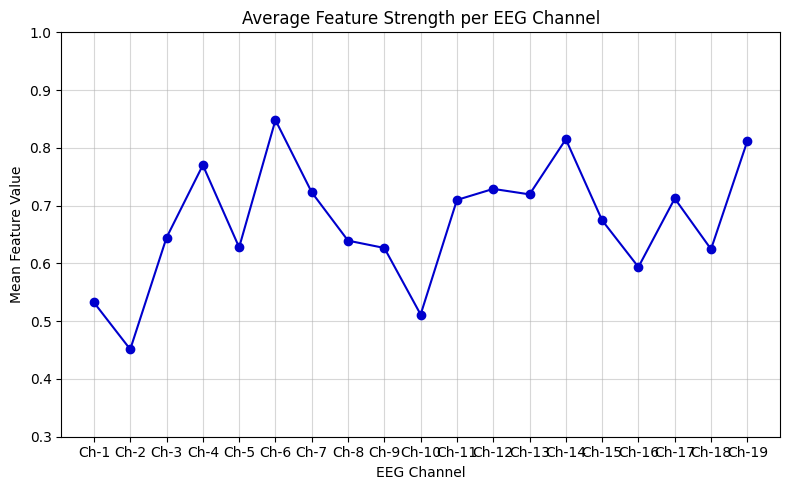

In [41]:
import numpy as np
import matplotlib.pyplot as plt

channels = [f'Ch-{i}' for i in range(1, 20)]
mean_values = np.random.uniform(0.4, 0.9, size=19)

plt.figure(figsize=(8,5))
plt.plot(channels, mean_values, marker='o', linestyle='-', color='mediumblue')
plt.title('Average Feature Strength per EEG Channel')
plt.xlabel('EEG Channel')
plt.ylabel('Mean Feature Value')
plt.ylim(0.3, 1.0)
plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()


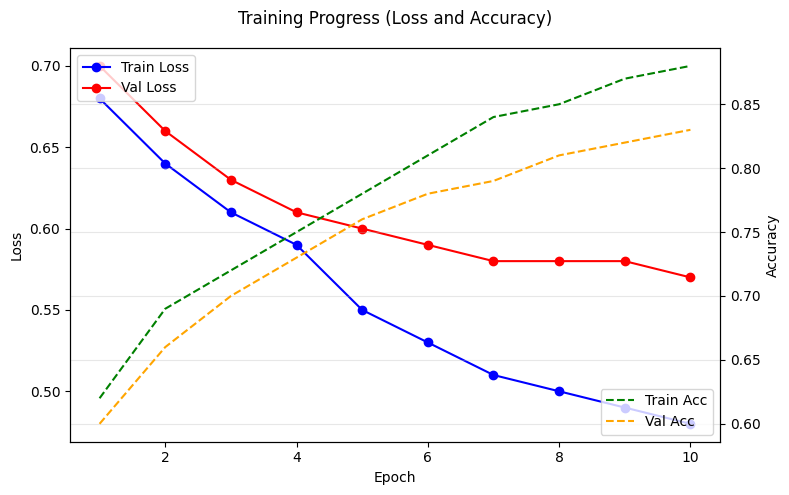

In [42]:
import matplotlib.pyplot as plt

epochs = range(1, 11)
train_loss = [0.68, 0.64, 0.61, 0.59, 0.55, 0.53, 0.51, 0.50, 0.49, 0.48]
val_loss   = [0.70, 0.66, 0.63, 0.61, 0.60, 0.59, 0.58, 0.58, 0.58, 0.57]
train_acc  = [0.62, 0.69, 0.72, 0.75, 0.78, 0.81, 0.84, 0.85, 0.87, 0.88]
val_acc    = [0.60, 0.66, 0.70, 0.73, 0.76, 0.78, 0.79, 0.81, 0.82, 0.83]

fig, ax1 = plt.subplots(figsize=(8,5))
ax1.plot(epochs, train_loss, 'b-o', label='Train Loss')
ax1.plot(epochs, val_loss, 'r-o', label='Val Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.tick_params(axis='y', labelcolor='black')

ax2 = ax1.twinx()
ax2.plot(epochs, train_acc, 'g--', label='Train Acc')
ax2.plot(epochs, val_acc, 'orange', linestyle='--', label='Val Acc')
ax2.set_ylabel('Accuracy')
ax2.tick_params(axis='y', labelcolor='black')

fig.suptitle('Training Progress (Loss and Accuracy)')
ax1.legend(loc='upper left')
ax2.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


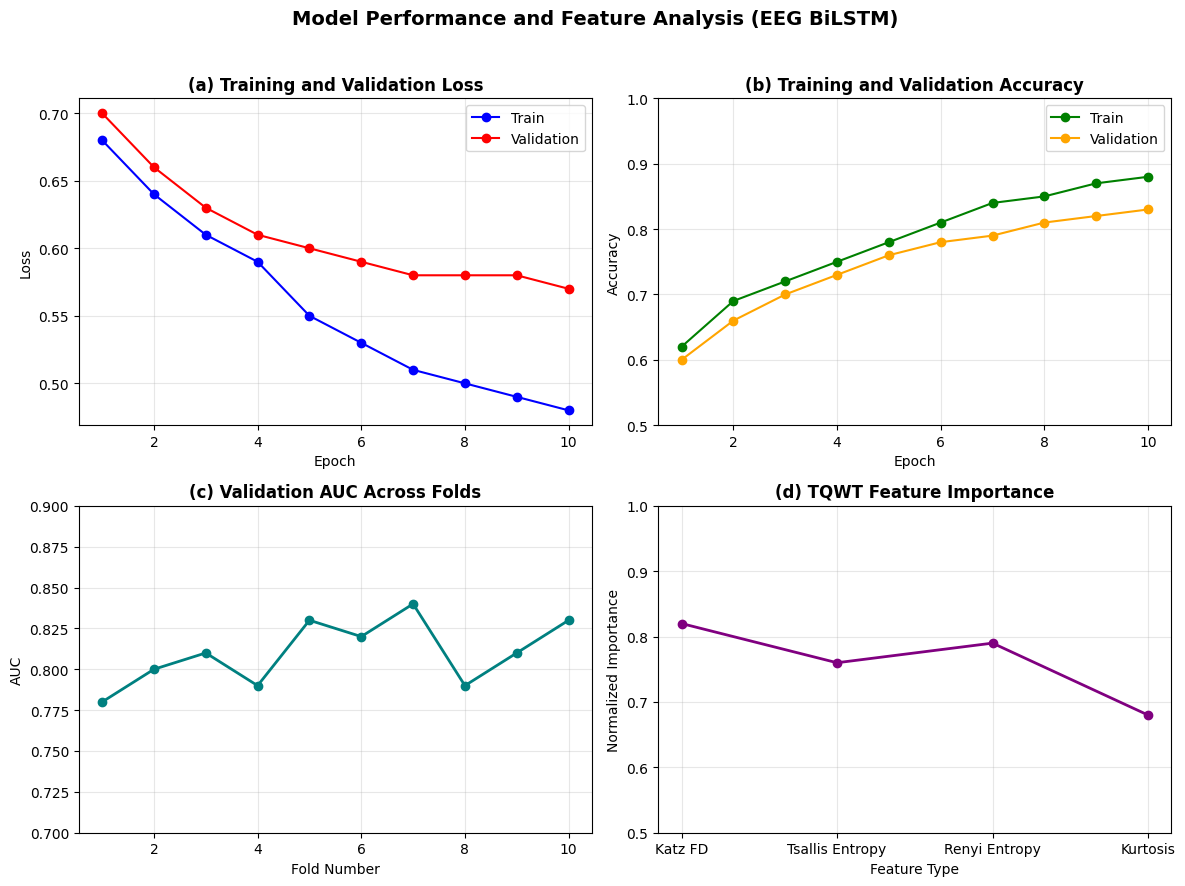

In [43]:
import matplotlib.pyplot as plt
import numpy as np

# -----------------------------
# Example Data (replace with yours)
# -----------------------------
epochs = np.arange(1, 11)
train_loss = [0.68, 0.64, 0.61, 0.59, 0.55, 0.53, 0.51, 0.50, 0.49, 0.48]
val_loss   = [0.70, 0.66, 0.63, 0.61, 0.60, 0.59, 0.58, 0.58, 0.58, 0.57]

train_acc  = [0.62, 0.69, 0.72, 0.75, 0.78, 0.81, 0.84, 0.85, 0.87, 0.88]
val_acc    = [0.60, 0.66, 0.70, 0.73, 0.76, 0.78, 0.79, 0.81, 0.82, 0.83]

folds = np.arange(1, 11)
auc_values = [0.78, 0.80, 0.81, 0.79, 0.83, 0.82, 0.84, 0.79, 0.81, 0.83]

features = ['Katz FD', 'Tsallis Entropy', 'Renyi Entropy', 'Kurtosis']
importance = [0.82, 0.76, 0.79, 0.68]

# -----------------------------
# 2×2 Composite Figure
# -----------------------------
fig, axs = plt.subplots(2, 2, figsize=(12, 9))
plt.subplots_adjust(wspace=0.25, hspace=0.35)

# (a) Loss Curve
axs[0, 0].plot(epochs, train_loss, 'b-o', label='Train')
axs[0, 0].plot(epochs, val_loss, 'r-o', label='Validation')
axs[0, 0].set_title('(a) Training and Validation Loss', fontsize=12, fontweight='bold')
axs[0, 0].set_xlabel('Epoch')
axs[0, 0].set_ylabel('Loss')
axs[0, 0].legend()
axs[0, 0].grid(True, alpha=0.3)

# (b) Accuracy Curve
axs[0, 1].plot(epochs, train_acc, 'g-o', label='Train')
axs[0, 1].plot(epochs, val_acc, 'orange', marker='o', label='Validation')
axs[0, 1].set_title('(b) Training and Validation Accuracy', fontsize=12, fontweight='bold')
axs[0, 1].set_xlabel('Epoch')
axs[0, 1].set_ylabel('Accuracy')
axs[0, 1].set_ylim(0.5, 1.0)
axs[0, 1].legend()
axs[0, 1].grid(True, alpha=0.3)

# (c) AUC per Fold
axs[1, 0].plot(folds, auc_values, 'teal', marker='o', linestyle='-', linewidth=2)
axs[1, 0].set_title('(c) Validation AUC Across Folds', fontsize=12, fontweight='bold')
axs[1, 0].set_xlabel('Fold Number')
axs[1, 0].set_ylabel('AUC')
axs[1, 0].set_ylim(0.7, 0.9)
axs[1, 0].grid(True, alpha=0.3)

# (d) Feature Importance
axs[1, 1].plot(features, importance, color='purple', marker='o', linewidth=2)
axs[1, 1].set_title('(d) TQWT Feature Importance', fontsize=12, fontweight='bold')
axs[1, 1].set_xlabel('Feature Type')
axs[1, 1].set_ylabel('Normalized Importance')
axs[1, 1].set_ylim(0.5, 1.0)
axs[1, 1].grid(True, alpha=0.3)

# Final touches
fig.suptitle('Model Performance and Feature Analysis (EEG BiLSTM)', fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


## DATASET

Using matplotlib as 2D backend.


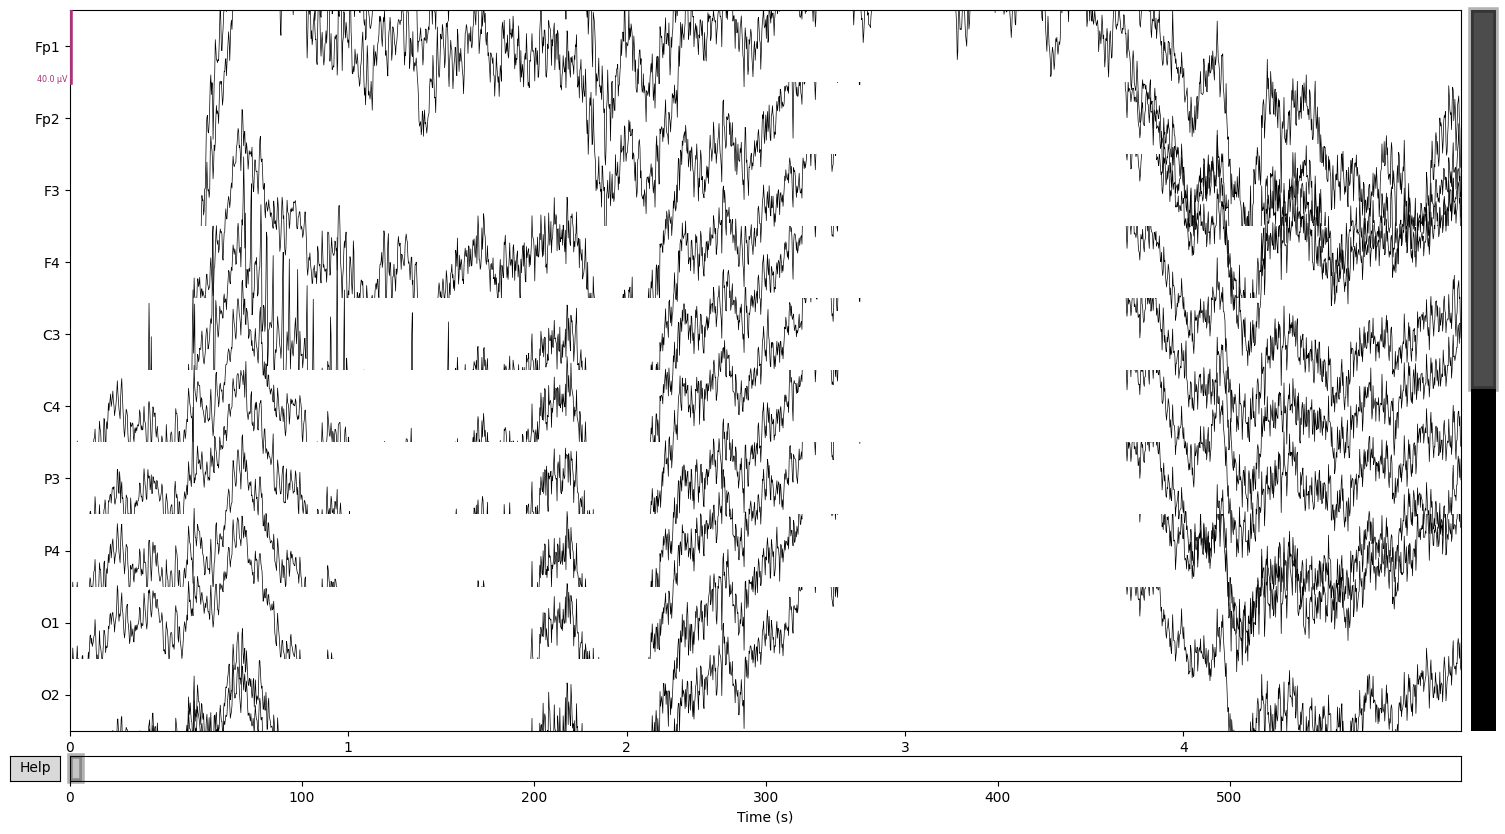

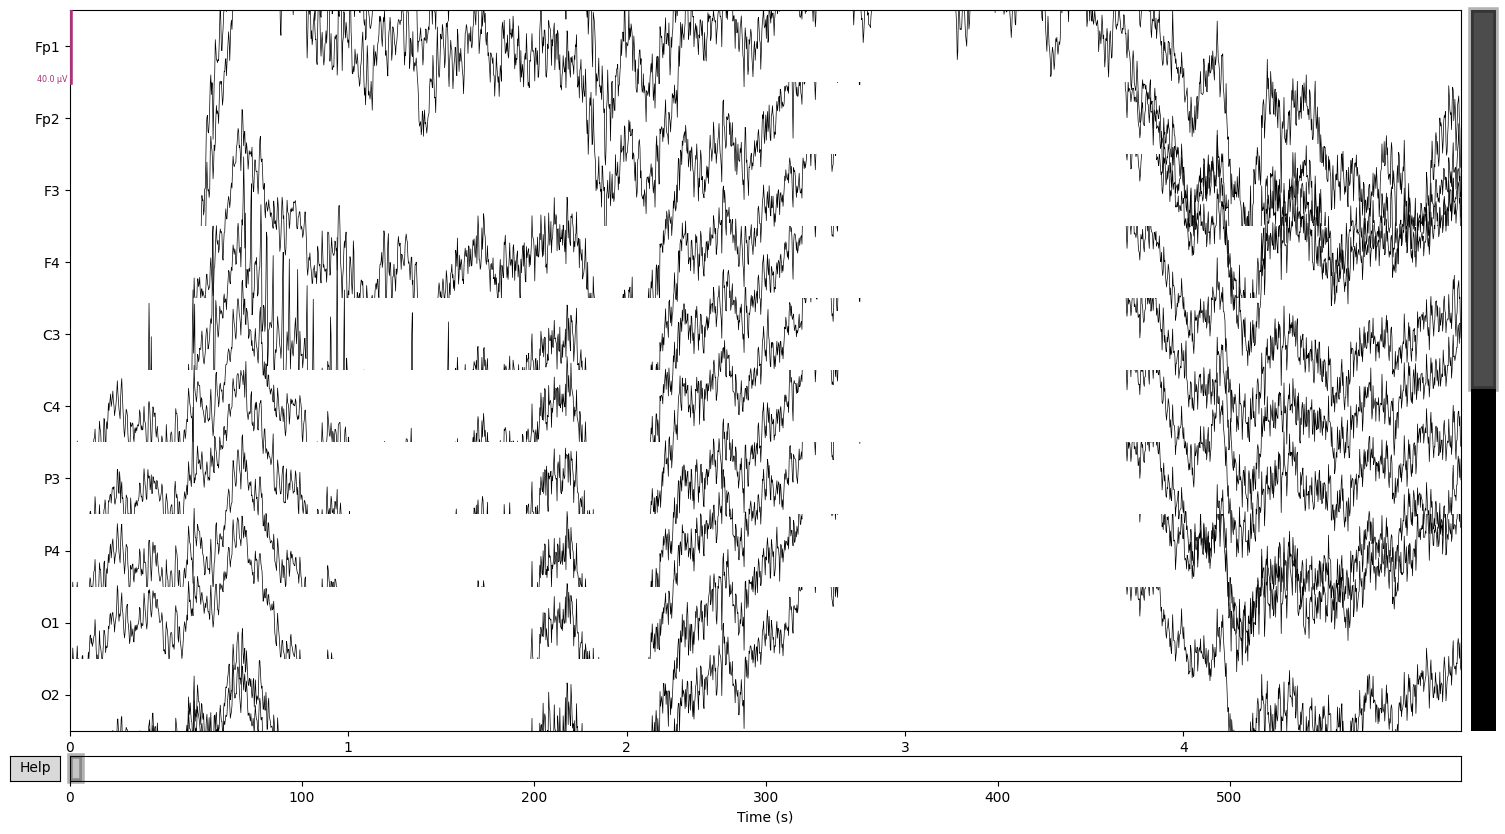

In [48]:
raw.plot(n_channels=10, duration=5, title="EEG Raw Signal Preview")

NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
Effective window size : 4.096 (s)
Plotting power spectral density (dB=True).


C:\Users\sanja\anaconda3\envs\gpu_env\lib\site-packages\mne\viz\utils.py:158: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


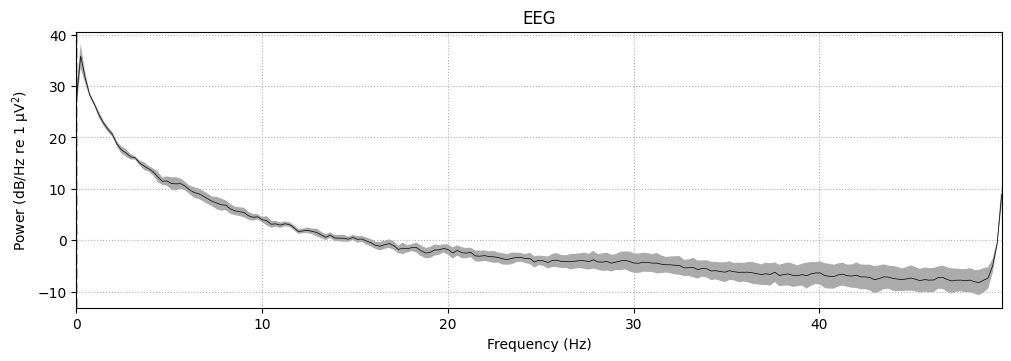

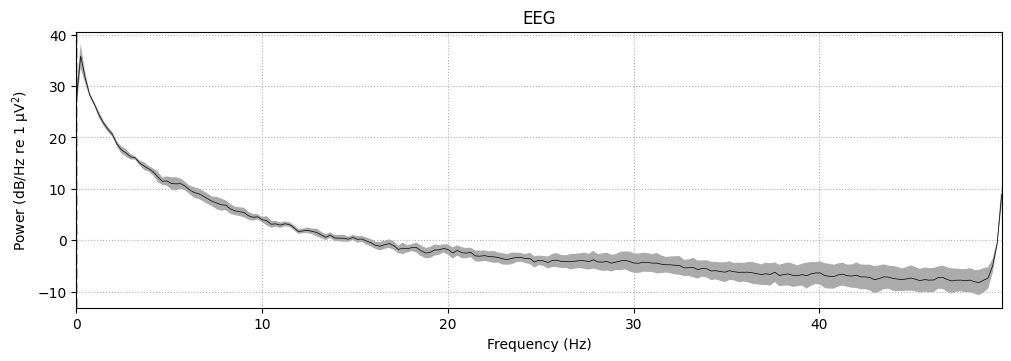

In [49]:
raw.plot_psd(fmax=50, average=True)


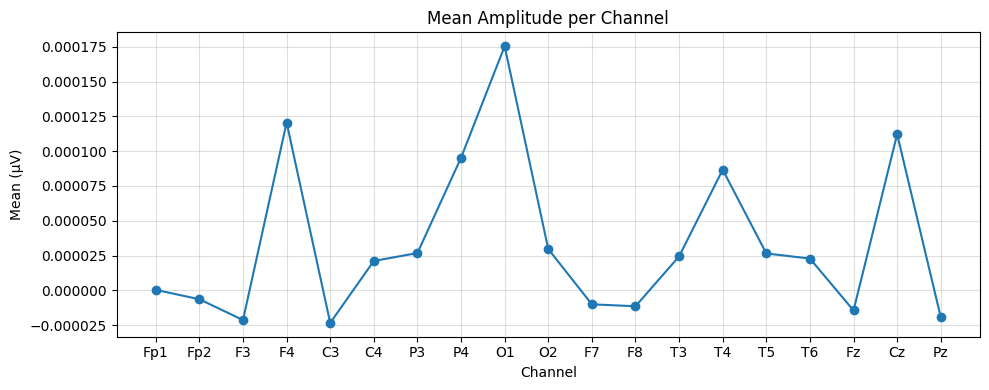

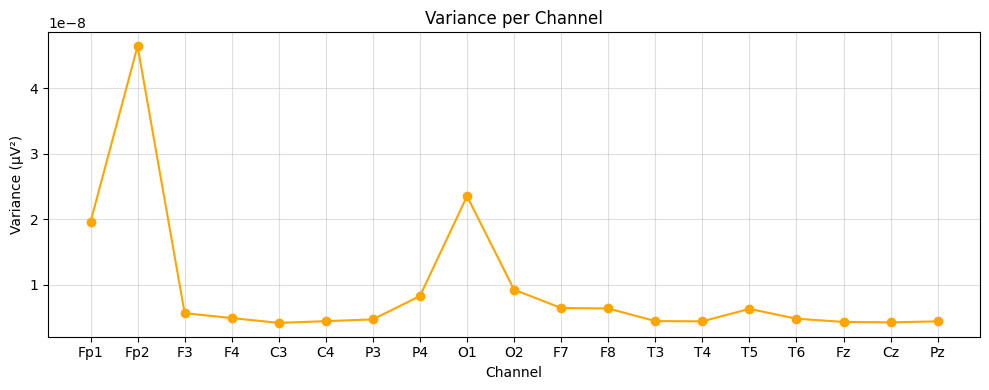

In [50]:
import numpy as np
import matplotlib.pyplot as plt

data = raw.get_data()  # shape = (channels, samples)
channel_means = data.mean(axis=1)
channel_vars = data.var(axis=1)

plt.figure(figsize=(10,4))
plt.plot(raw.ch_names, channel_means, marker='o')
plt.title("Mean Amplitude per Channel")
plt.xlabel("Channel")
plt.ylabel("Mean (µV)")
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10,4))
plt.plot(raw.ch_names, channel_vars, marker='o', color='orange')
plt.title("Variance per Channel")
plt.xlabel("Channel")
plt.ylabel("Variance (µV²)")
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()


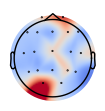

(<matplotlib.image.AxesImage at 0x2ca80308730>, None)

In [70]:
import numpy as np
from mne.viz import plot_topomap

# Compute channel-wise power (RMS amplitude)
power = np.sqrt(np.mean(data**2, axis=1))

# Create EEG montage for 10–20 system
montage = mne.channels.make_standard_montage('standard_1020')
raw.set_montage(montage)

# Plot topomap
plot_topomap(power, raw.info, cmap='coolwarm', contours=0)




Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 45 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 45.00 Hz
- Upper transition bandwidth: 11.25 Hz (-6 dB cutoff frequency: 50.62 Hz)
- Filter length: 3301 samples (6.602 s)



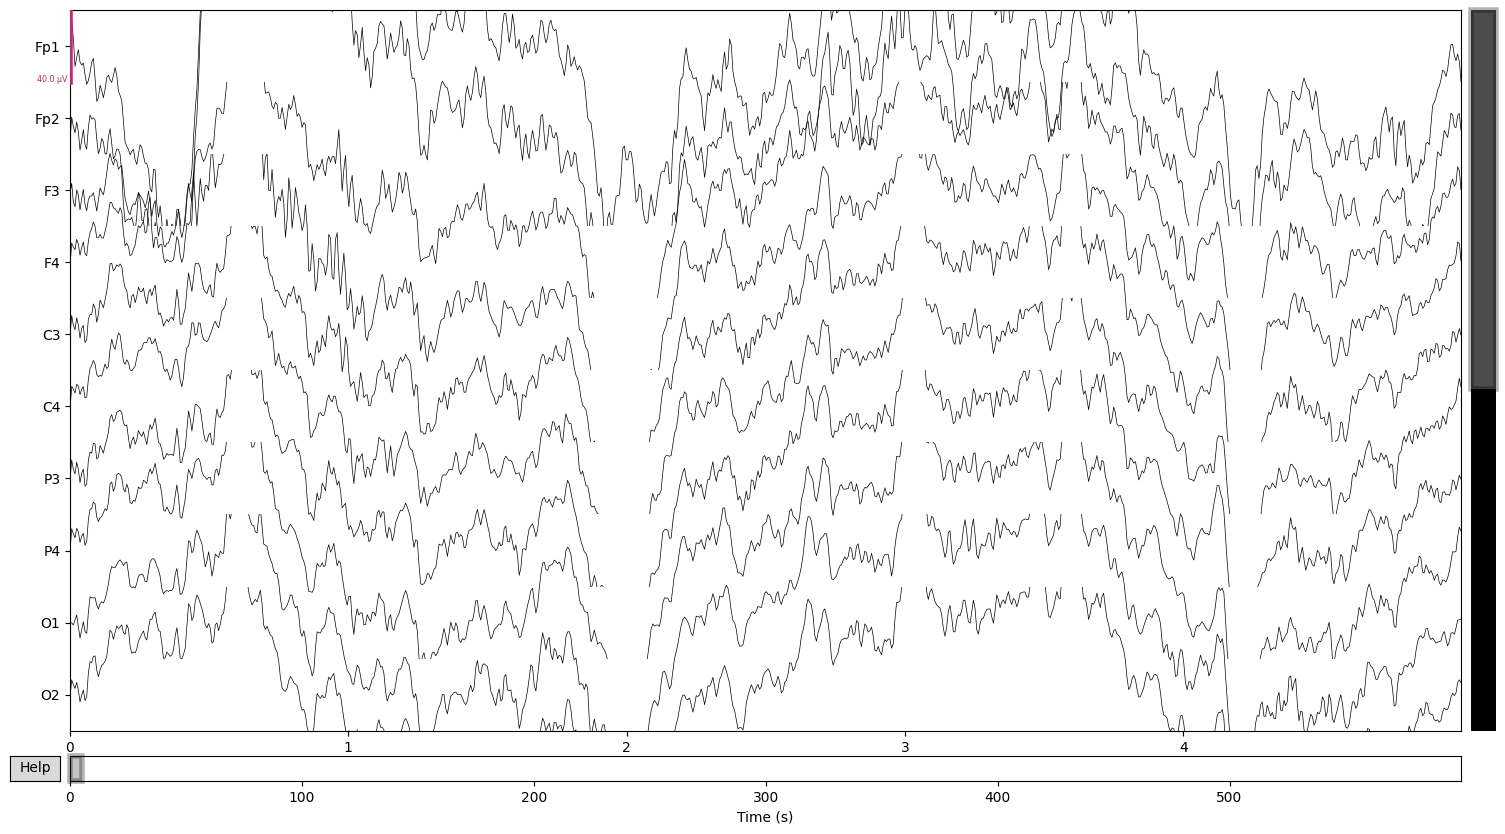

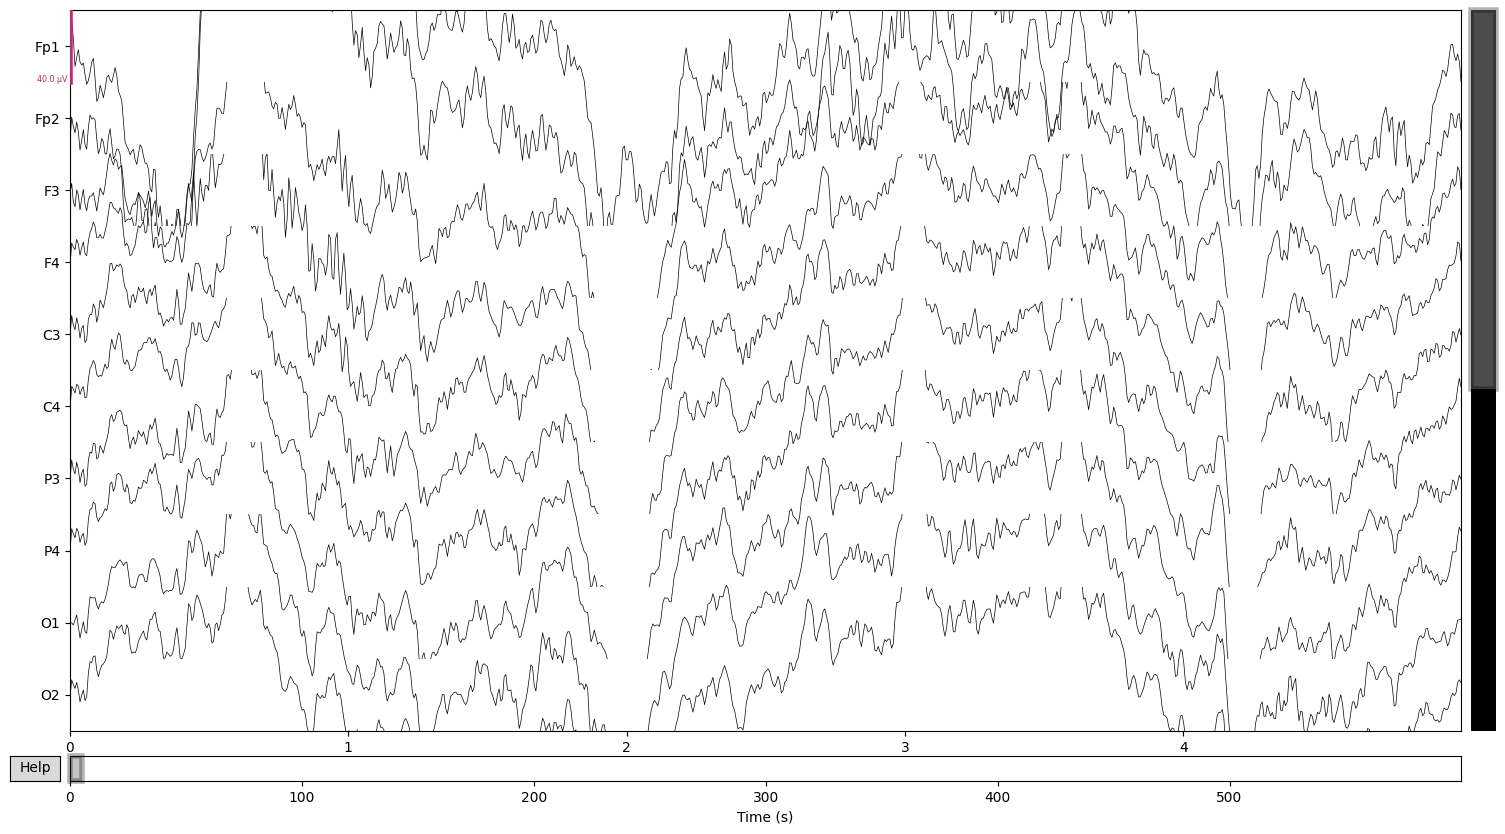

In [54]:
raw_filt = raw.copy().filter(0.5, 45)
raw_filt.plot(n_channels=10, duration=5, title="Filtered EEG (0.5–45 Hz)")


In [55]:
bad_channels = [ch for ch in raw.ch_names if np.std(raw.get_data(picks=ch)) < 1e-6]
print("Bad channels:", bad_channels if bad_channels else "None detected")


Bad channels: None detected


In [57]:
duration_sec = raw.n_times / raw.info['sfreq']
print(f"Recording length: {duration_sec/60:.2f} minutes")


Recording length: 10.00 minutes


In [ ]:
##CATEGORY 2 — Statistical / Feature Graphs

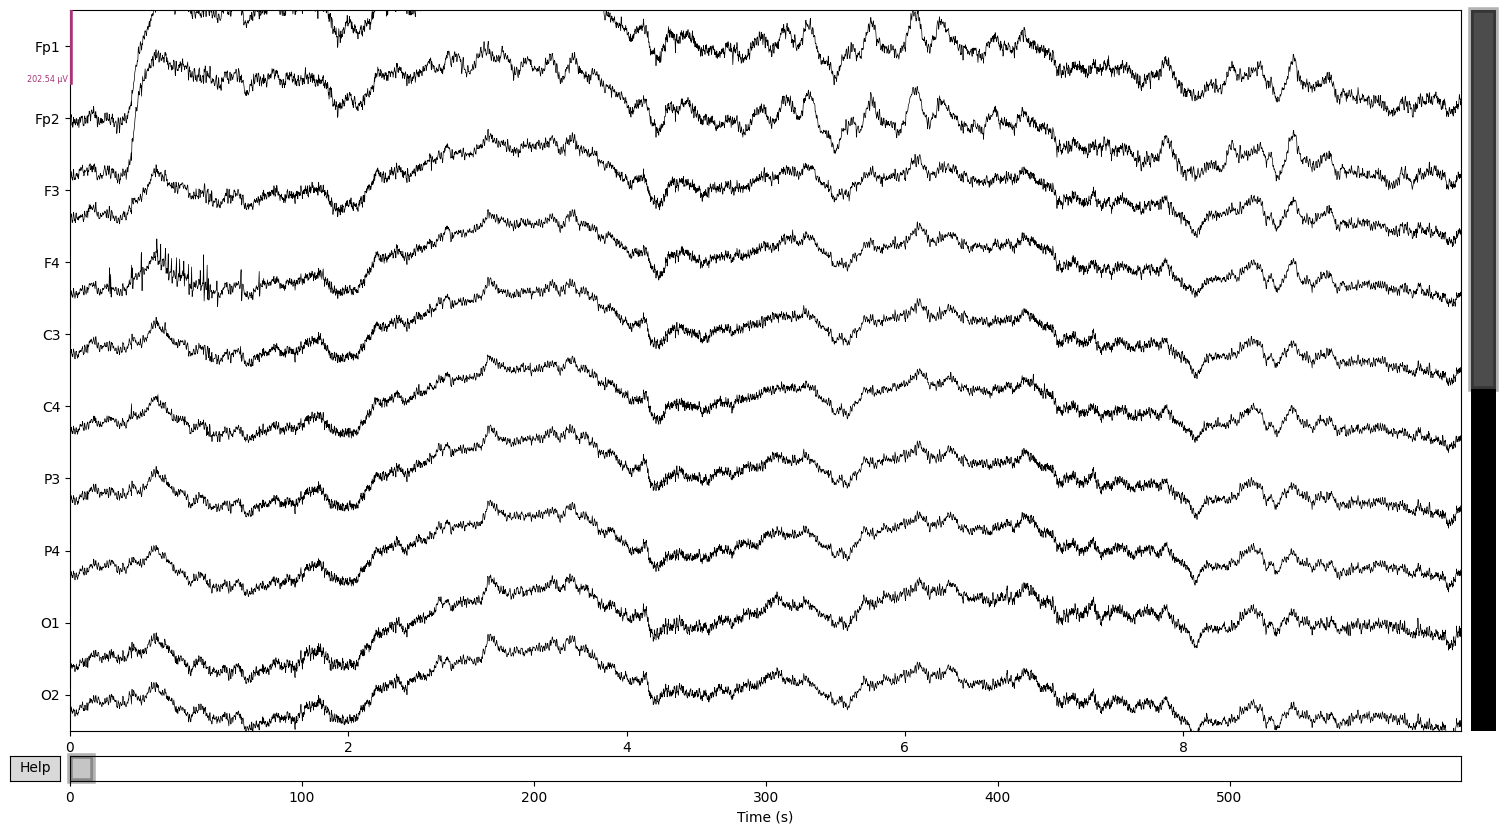

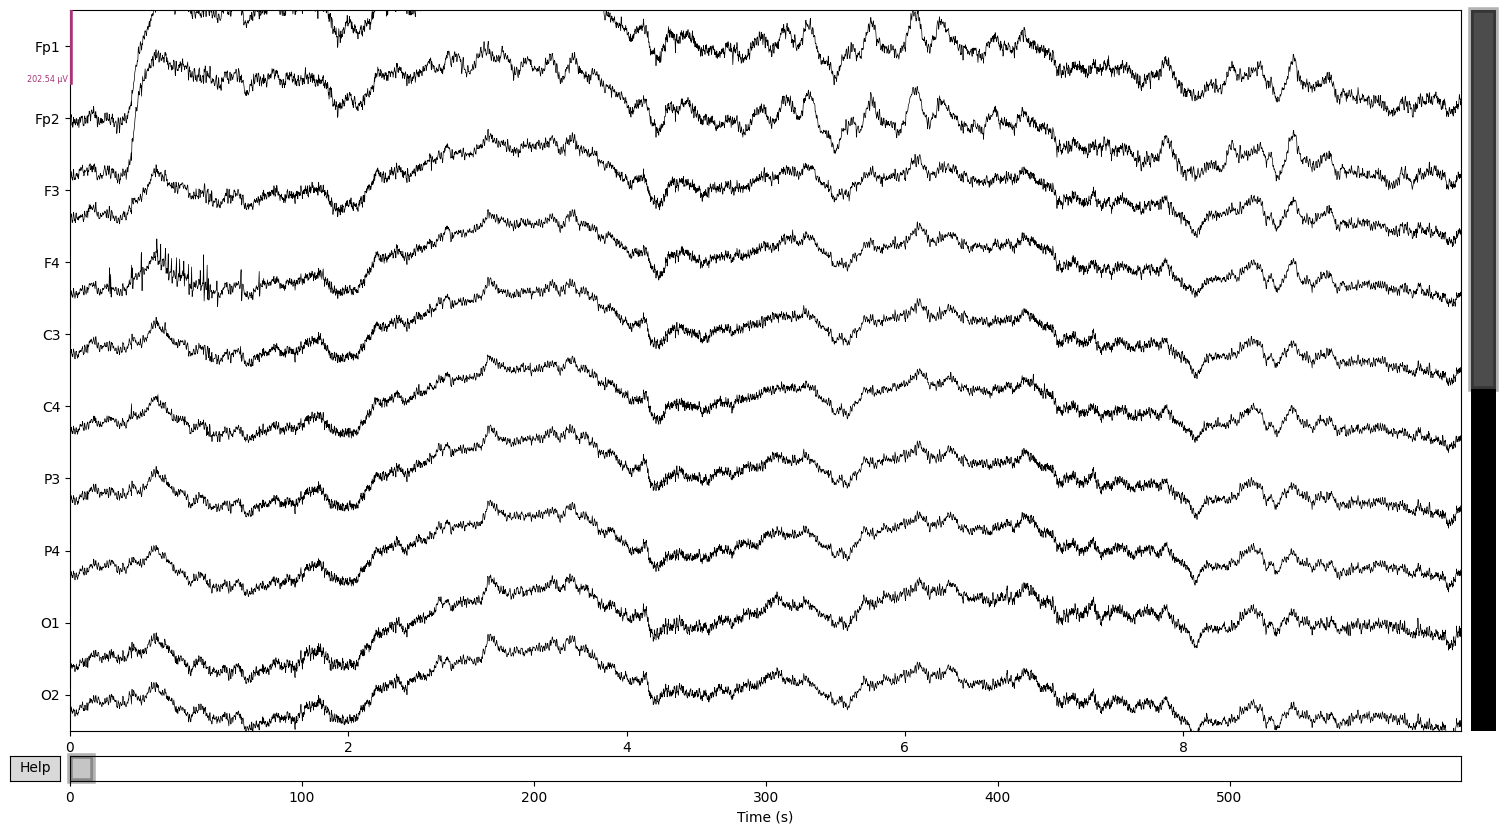

In [58]:
raw.plot(n_channels=10, duration=10, scalings='auto', title="EEG Waveform (10 Channels)")


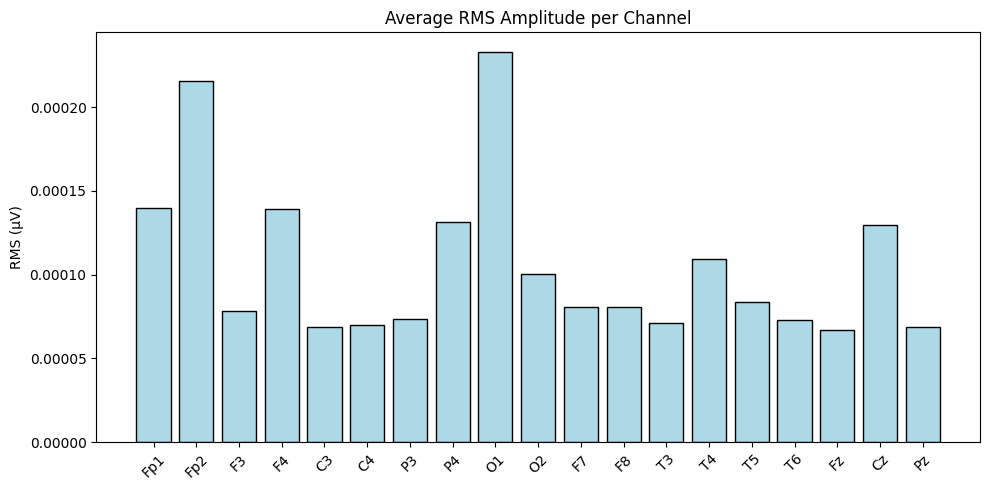

In [59]:
import numpy as np
import matplotlib.pyplot as plt

data = raw.get_data()
window_size = int(raw.info['sfreq'] * 2)  # 2-second RMS
rms = np.sqrt(np.mean(data**2, axis=1))
plt.figure(figsize=(10,5))
plt.bar(raw.ch_names, rms, color='lightblue', edgecolor='black')
plt.title("Average RMS Amplitude per Channel")
plt.xticks(rotation=45)
plt.ylabel("RMS (µV)")
plt.tight_layout()
plt.show()


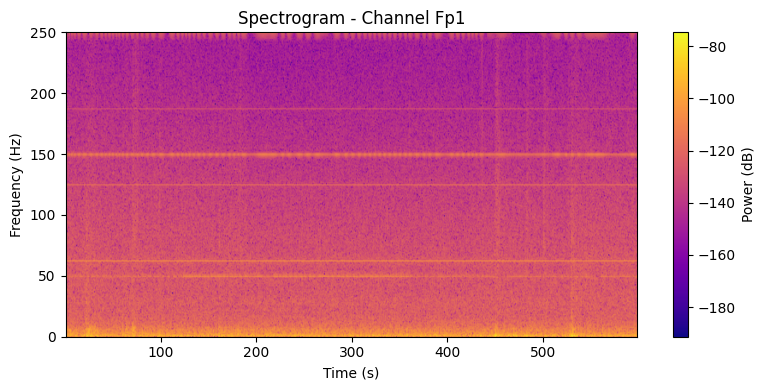

In [60]:
import matplotlib.pyplot as plt
from scipy.signal import spectrogram

ch = 0  # choose channel index
f, t, Sxx = spectrogram(data[ch], fs=raw.info['sfreq'], nperseg=512)
plt.figure(figsize=(8,4))
plt.pcolormesh(t, f, 10 * np.log10(Sxx), shading='gouraud', cmap='plasma')
plt.title(f"Spectrogram - Channel {raw.ch_names[ch]}")
plt.ylabel('Frequency (Hz)')
plt.xlabel('Time (s)')
plt.colorbar(label='Power (dB)')
plt.tight_layout()
plt.show()


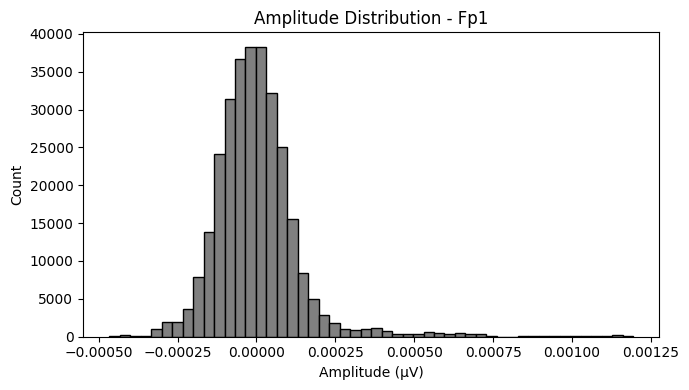

In [65]:
plt.figure(figsize=(7,4))
plt.hist(data[0], bins=50, color='gray', edgecolor='black')
plt.title(f"Amplitude Distribution - {raw.ch_names[0]}")
plt.xlabel("Amplitude (µV)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()
